# SUNSHIELD — GRU Notebook 3: Anomaly Definition

**Place in Dr. Mai's workflow:** the **"Anomaly definition using different σ"** box, for the GRU. Same rule and
settings as LSTM Notebook 3, so the models are compared on the same definition.

```
Actual line          ─► anomaly definition (k = 1, 1.5, 2, 2.5, 3) ─► Actual 0/1     (one column per k)
GRU predicted line ─► anomaly definition (k = 1, 1.5, 2, 2.5, 3) ─► Predicted 0/1  (one column per k)
                                                                         └─► GRU Notebook 4: F1 per k → best k
```

**The rule:** a reading is an anomaly (= 1) if it is outside mean ± k·std of **all the readings before it**
(`Data[0 … t-1]`), in the same inverter and the same split.

| Step | What happens | Output |
|---|---|---|
| 1 | Reuse the anomaly function from LSTM Notebook 3 unchanged (series → 0/1) | function + small test |
| 2 | Same rule: mean and std of PREVIOUS readings only | — |
| 3 | Same `MODE` and `PRUNING` settings as the LSTM | settings in first cell |
| 4 | Apply to the ACTUAL line for k = 1, 1.5, 2, 2.5, 3 | `actual_anomaly` columns |
| 5 | Apply to the GRU PREDICTED line separately (its own history), same k values | `predicted_anomaly` columns |
| 6 | Plot showing the mean ± k·std band for every k | `sigma_bands.png` |
| 7 | File 2: Training Thresholding (actual 0/1 + predicted 0/1 for every k) | `2_GRU_Training_Output_Thresholding.csv` |
| 8 | Save and zip outputs | `gru_step3_outputs.zip` |

## Settings

In [1]:
import os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODEL_NAME = 'GRU'
MODE = 'level'              # same as the LSTM. 'level': test the raw value (kW)
                            #                   'change': test the change from the previous reading
K_VALUES = [1, 1.5, 2, 2.5, 3]
PRUNING = False             # same as the LSTM. True: an anomaly is left out of the mean/std of later readings
MIN_HISTORY = 2             # same as the LSTM. A std needs at least 2 previous readings; before that = 0

SHOW_K = 2.5                # k whose anomalies are shown as red dots in the band plot (2.5 = best k of the LSTM;
                            # the GRU's own best k is chosen in Notebook 4)
INVERTER = 'LlT2YUhhzqhg5Sw'  # inverter of the band plot, the same one as the LSTM plots

SPLITS = ['train', 'val', 'test']
OUT_DIR = 'gru_step3_outputs'
os.makedirs(OUT_DIR, exist_ok=True)

# Chart style (light surface, recessive grid); actual = blue, anomalies = red, as in the LSTM plots
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, RED = '#2a78d6', '#e34948'
BAND_BLUES = ['#184f95', '#2a78d6', '#6da7ec', '#9ec5f4', '#cde2fb']     # k = 1 (dark) … k = 3 (light)
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
                     'axes.titlecolor': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'legend.frameon': False, 'font.size': 10})

## Upload GRU Notebook 2 outputs

Run the cell below, click **Choose Files** and select `gru_step2_outputs.zip`.

In [2]:
from google.colab import files
uploaded = files.upload()
shutil.unpack_archive(list(uploaded)[0], 'gru_step2_outputs', 'zip')

predictions = {s: pd.read_csv(f'gru_step2_outputs/prediction_{s}.csv', parse_dates=['DATE_TIME'])
                  .sort_values(['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)
               for s in SPLITS}
for s in SPLITS:
    print(f'{s:5s}: {len(predictions[s]):,} readings, {predictions[s].groupby(["PLANT_ID", "SOURCE_KEY"]).ngroups} inverters')

train: 44,753 readings, 44 inverters
val  : 11,968 readings, 44 inverters
test : 11,286 readings, 44 inverters


## Steps 1, 2 — The anomaly function (copied unchanged from LSTM Notebook 3)

For every reading, in time order:
1. compute the mean and std of the readings **before** it (never the reading itself, never the future),
2. flag 1 if the reading is above `mean + k·std` or below `mean − k·std`, otherwise 0,
3. add the reading to the history for the next readings.

The history is kept as running sums (count, sum, sum of squares); the std is the sample std (÷ n − 1), like pandas.

In [3]:
def flag_anomalies(series, k, mode=MODE, pruning=PRUNING, min_history=MIN_HISTORY):
    '''series (in time order) -> numpy array of 0/1.
    1 = abnormal rise or drop: value outside mean ± k·std of the PREVIOUS readings only.'''
    x = np.asarray(series, dtype=float)
    if mode == 'change':
        x = np.diff(x, prepend=np.nan)          # change from the previous reading; the first has none
    elif mode != 'level':
        raise ValueError("MODE must be 'level' or 'change'")

    flags = np.zeros(len(x), dtype=int)
    n, total, total_sq = 0, 0.0, 0.0            # history so far: count, sum, sum of squares
    for t, value in enumerate(x):
        if np.isnan(value):
            continue
        if n >= min_history:
            mean = total / n
            std = np.sqrt(max((total_sq - n * mean ** 2) / (n - 1), 0.0))   # sample std, like pandas
            if value > mean + k * std or value < mean - k * std:
                flags[t] = 1
        if not (pruning and flags[t]):          # with pruning, anomalies stay out of the history
            n += 1
            total += value
            total_sq += value ** 2
    return flags

### Small test (the same as LSTM Notebook 3)

A flat line with a big spike (index 6), a smaller spike (index 8) and a dip (index 10). It checks that the rise and
the drop are found, that the result equals a plain pandas calculation, that **no future reading is used**, and
that pruning finds the smaller spike that the big one hides.

In [4]:
test = np.array([10, 12, 9, 11, 10, 12, 40, 10, 25, 11, -15, 11], dtype=float)
flags = flag_anomalies(test, k=2, mode='level', pruning=False)
print('series                  :', test.astype(int).tolist())
print('flags                   :', flags.tolist())
assert flags[6] == 1 and flags[10] == 1, 'the rise and the drop must be flagged'
assert flags[[0, 1, 2, 3, 4, 5, 7, 8, 9, 11]].sum() == 0, 'normal readings must be 0'

s = pd.Series(test)
mean_prev = s.expanding(MIN_HISTORY).mean().shift(1)
std_prev = s.expanding(MIN_HISTORY).std().shift(1)
pandas_flags = ((s > mean_prev + 2 * std_prev) | (s < mean_prev - 2 * std_prev)).astype(int).to_numpy()
assert (pandas_flags == flags).all()

changed_future = test.copy()
changed_future[7:] = 1000
assert (flag_anomalies(changed_future, k=2, mode='level')[:7] == flags[:7]).all()

pruned = flag_anomalies(test, k=2, mode='level', pruning=True)
print('flags with PRUNING=True :', pruned.tolist())
assert pruned[8] == 1
print("flags with MODE='change':", flag_anomalies(test, k=2, mode='change').tolist())
print('All tests passed.')

series                  : [10, 12, 9, 11, 10, 12, 40, 10, 25, 11, -15, 11]
flags                   : [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0]
flags with PRUNING=True : [0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0]
flags with MODE='change': [0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0]
All tests passed.


## Step 3 — Same `MODE` and `PRUNING` as the LSTM

In [5]:
LSTM_SETTINGS = {'MODE': 'level', 'PRUNING': False, 'MIN_HISTORY': 2}
mine = {'MODE': MODE, 'PRUNING': PRUNING, 'MIN_HISTORY': MIN_HISTORY}
print(f'{MODEL_NAME}: {mine}\nLSTM : {LSTM_SETTINGS}\nSame settings: {mine == LSTM_SETTINGS}')

GRU: {'MODE': 'level', 'PRUNING': False, 'MIN_HISTORY': 2}
LSTM : {'MODE': 'level', 'PRUNING': False, 'MIN_HISTORY': 2}
Same settings: True


## Steps 4 and 5 — Apply to the ACTUAL line and to the GRU PREDICTED line, each one alone

- every **inverter** is its own series, in time order
- every **split** starts its history at its first reading
- the actual line uses the history of the actual line, the predicted line the history of the predicted line

Column names: `actual_anomaly_k1` … `actual_anomaly_k3` and `predicted_anomaly_k1` … `predicted_anomaly_k3`.

In [6]:
LINES = {'actual': 'ACTUAL_AC_POWER_kW', 'predicted': 'PREDICTED_AC_POWER_kW'}

def add_anomaly_columns(df):
    out = df.copy()
    groups = out.groupby(['PLANT_ID', 'SOURCE_KEY'], sort=False).indices.values()
    for line, column in LINES.items():
        values = out[column].to_numpy()
        for k in K_VALUES:
            col = f'{line}_anomaly_k{k:g}'
            out[col] = 0
            for rows in groups:
                out.loc[rows, col] = flag_anomalies(values[rows], k)
    return out

anomalies = {s: add_anomaly_columns(predictions[s]) for s in SPLITS}

rate = pd.DataFrame({
    (s, line): [100 * anomalies[s][f'{line}_anomaly_k{k:g}'].mean() for k in K_VALUES]
    for s in SPLITS for line in LINES}, index=[f'k = {k:g}' for k in K_VALUES])
rate.columns.names = ['split', 'line']
print('% of readings flagged as anomaly (1):')
rate.round(2)

% of readings flagged as anomaly (1):


split    train              val             test          
line    actual predicted actual predicted actual predicted
k = 1    43.54     41.49  36.82     37.50  41.55     41.91
k = 1.5  10.94     12.03  11.66     13.79  12.33     15.59
k = 2     1.84      1.38   4.90      4.96   5.58      3.51
k = 2.5   0.32      0.69   2.03      1.84   2.29      1.56
k = 3     0.14      0.39   0.80      0.55   1.23      0.97

## Step 6 — The mean ± k·std band for every k

The actual line of one inverter (`INVERTER`) in the test split, the mean of the previous readings (dashed), and the
band mean ± k·std for every k. A reading outside the band of a k is an anomaly for that k; the red dots are the
anomalies for `SHOW_K`. `history_bands` repeats the rule of `flag_anomalies`, and the check confirms it gives
exactly the same 0/1.

Same 0/1 as flag_anomalies: True


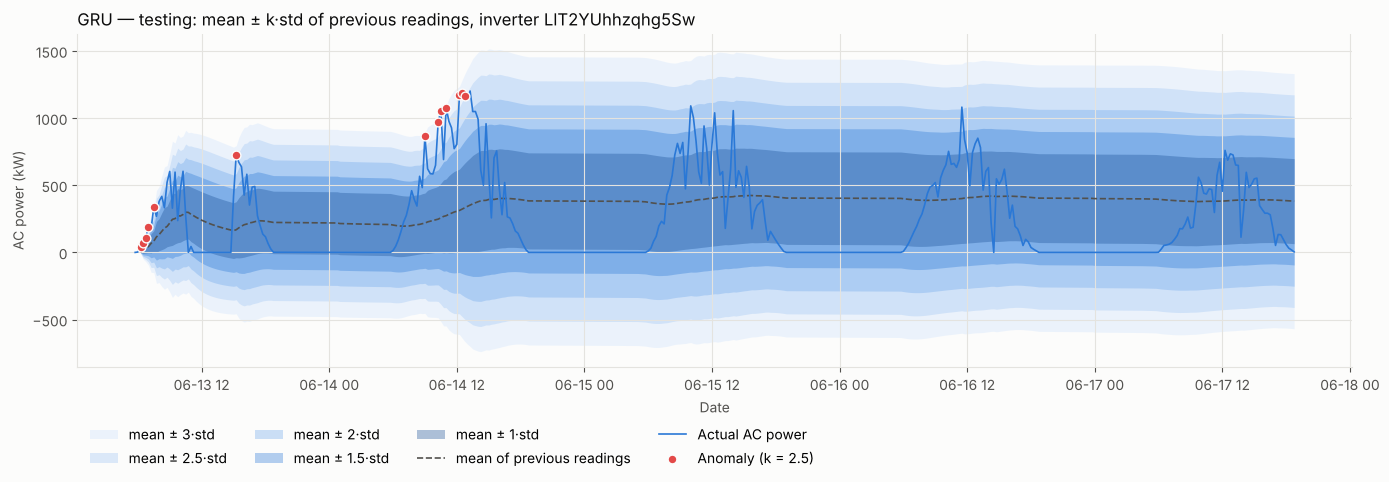

In [7]:
def history_bands(series, k):
    '''Mean and std of the PREVIOUS readings for every point (same rule and settings as flag_anomalies).'''
    x = np.asarray(series, dtype=float)
    if MODE == 'change':
        x = np.diff(x, prepend=np.nan)
    mean_prev, std_prev = np.full(len(x), np.nan), np.full(len(x), np.nan)
    n, total, total_sq = 0, 0.0, 0.0
    for t, value in enumerate(x):
        if np.isnan(value):
            continue
        flagged = False
        if n >= MIN_HISTORY:
            mean_prev[t] = total / n
            std_prev[t] = np.sqrt(max((total_sq - n * mean_prev[t] ** 2) / (n - 1), 0.0))
            flagged = abs(value - mean_prev[t]) > k * std_prev[t]
        if not (PRUNING and flagged):
            n += 1
            total += value
            total_sq += value ** 2
    return x, mean_prev, std_prev

d = anomalies['test']
d = d[d['SOURCE_KEY'] == INVERTER].sort_values('DATE_TIME')
x, mean_show, std_show = history_bands(d['ACTUAL_AC_POWER_kW'], SHOW_K)
show_col = f'actual_anomaly_k{SHOW_K:g}'
same = ((np.abs(x - mean_show) > SHOW_K * std_show).astype(int) == d[show_col].to_numpy()).all()
print('Same 0/1 as flag_anomalies:', same)

fig, ax = plt.subplots(figsize=(14, 5))
for k, color in sorted(zip(K_VALUES, BAND_BLUES), reverse=True):        # widest band first
    _, mean_k, std_k = history_bands(d['ACTUAL_AC_POWER_kW'], k)
    ax.fill_between(d['DATE_TIME'], mean_k - k * std_k, mean_k + k * std_k, color=color, alpha=0.35,
                    linewidth=0, label=f'mean ± {k:g}·std')
ax.plot(d['DATE_TIME'], mean_show, color=INK_2, linestyle='--', linewidth=1.2, label='mean of previous readings')
ax.plot(d['DATE_TIME'], x, color=BLUE, linewidth=1.2,
        label='Actual AC power' if MODE == 'level' else 'Change in actual AC power')
out = d[show_col].to_numpy() == 1
ax.scatter(d['DATE_TIME'][out], x[out], s=40, color=RED, edgecolors=SURFACE, linewidths=1, zorder=3,
           label=f'Anomaly (k = {SHOW_K:g})')
ax.set_title(f'{MODEL_NAME} — testing: mean ± k·std of previous readings, inverter {INVERTER}', loc='left')
ax.set_xlabel('Date')
ax.set_ylabel('AC power (kW)' if MODE == 'level' else 'Change in AC power (kW per 15 min)')
ax.legend(loc='upper left', ncol=4, bbox_to_anchor=(0, -0.14))
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'sigma_bands.png'), dpi=150)
plt.show()

## Step 7 — File 2: Training Thresholding

Training split: inverter, time and the actual 0/1 and predicted 0/1 for **every k** (k is chosen from this file in
Notebook 4).

In [8]:
ID = ['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']
ALL_K = [f'{line}_anomaly_k{k:g}' for line in LINES for k in K_VALUES]
file2 = anomalies['train'][ID + ALL_K]
file2_name = f'2_{MODEL_NAME}_Training_Output_Thresholding.csv'
file2.to_csv(os.path.join(OUT_DIR, file2_name), index=False)
print(f'{file2_name}: {len(file2):,} rows, columns {list(file2.columns)}')

2_GRU_Training_Output_Thresholding.csv: 44,753 rows, columns ['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME', 'actual_anomaly_k1', 'actual_anomaly_k1.5', 'actual_anomaly_k2', 'actual_anomaly_k2.5', 'actual_anomaly_k3', 'predicted_anomaly_k1', 'predicted_anomaly_k1.5', 'predicted_anomaly_k2', 'predicted_anomaly_k2.5', 'predicted_anomaly_k3']


## Step 8 — Save and zip outputs

| File | Content | Used by |
|---|---|---|
| `anomaly_train.csv` / `anomaly_val.csv` / `anomaly_test.csv` | actual + predicted kW, and the 0/1 columns for every k | **GRU Notebook 4** |
| `2_GRU_Training_Output_Thresholding.csv` | File 2 | report |
| `anomaly_rate.csv` | % of readings flagged per split, line and k | report |
| `sigma_bands.png` | Step 6 plot | report |
| `settings.txt` | `MODE`, `PRUNING`, k values used | Notebook 4, report |

In [9]:
for s in SPLITS:
    anomalies[s].to_csv(os.path.join(OUT_DIR, f'anomaly_{s}.csv'), index=False)
rate.to_csv(os.path.join(OUT_DIR, 'anomaly_rate.csv'))
with open(os.path.join(OUT_DIR, 'settings.txt'), 'w') as f:
    f.write(f'MODEL = {MODEL_NAME}\nMODE = {MODE}\nPRUNING = {PRUNING}\nK_VALUES = {K_VALUES}\nMIN_HISTORY = {MIN_HISTORY}\n')

shutil.make_archive('gru_step3_outputs', 'zip', OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print(f'{f:45s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1e6:6.2f} MB')

files.download('gru_step3_outputs.zip')    # keep this file: GRU Notebook 4 needs it

2_GRU_Training_Output_Thresholding.csv          2.86 MB
anomaly_rate.csv                                0.00 MB
anomaly_test.csv                                0.97 MB
anomaly_train.csv                               3.82 MB
anomaly_val.csv                                 1.02 MB
settings.txt                                    0.00 MB
sigma_bands.png                                 0.19 MB
